# CS114 — Logistic Regression | Notebook cốt lõi (Library)
**Home Credit Default Risk — dữ liệu chung của nhóm**

Chạy trong **thư mục gốc repository** `Credit_risk_CS114` bằng kernel `.venv`.

**Quy trình:** Kiểm tra dữ liệu → `get_train_test_data(scale=True)` → Baseline → Stratified 3-Fold GridSearchCV → Test cố định → Confusion Matrix, ROC, PR → hệ số → xuất JSON.

- Không tự chia dữ liệu; không sửa `src/config.py`, `src/data_loader.py`, `src/metrics.py`.
- **Không có From Scratch**; chỉ dùng `sklearn.linear_model.LogisticRegression`.
- Không lựa chọn hyperparameter hay ngưỡng dựa trên tập Test. Kết quả CV hiện chỉ mang tính **thăm dò** do hạn chế của core hiện tại (nêu cuối notebook).

## 1. Nạp thư viện, kiểm tra dữ liệu và core chung
Dữ liệu gốc trong `data/`: `application_train.csv`, `bureau.csv`, `previous_application.csv`, `installments_payments.csv`, `POS_CASH_balance.csv`, `credit_card_balance.csv`. **Không cần `bureau_balance.csv` với core hiện tại.**

In [1]:
from pathlib import Path
import time, hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import (
    balanced_accuracy_score, roc_auc_score, average_precision_score,
    precision_score, recall_score, f1_score, accuracy_score,
    confusion_matrix, roc_curve, precision_recall_curve
)
from src.config import DATA_DIR, RANDOM_STATE, TEST_SIZE, RESULTS_DIR
from src.data_loader import get_train_test_data
from src.metrics import evaluate_and_save, plot_confusion_matrix

required_files = [
    'application_train.csv', 'bureau.csv', 'previous_application.csv',
    'installments_payments.csv', 'POS_CASH_balance.csv',
    'credit_card_balance.csv'
]
missing = [name for name in required_files if not (DATA_DIR / name).exists()]
if missing:
    raise FileNotFoundError('Thiếu file trong data/: ' + ', '.join(missing))

for core_name in ['config.py', 'data_loader.py', 'metrics.py']:
    core_path = Path('src') / core_name
    print(core_name, hashlib.sha256(core_path.read_bytes()).hexdigest()[:12])
print(f'Đủ 6 CSV | random_state={RANDOM_STATE} | test_size={TEST_SIZE}')

config.py 7f7537671fc4
data_loader.py 31cab3806b67
metrics.py 53ec6e9cbf94
Đủ 6 CSV | random_state=1 | test_size=0.25


## 2. Nạp dataset đã tổng hợp bằng pipeline chung
Đây là cell nặng nhất: core đọc 6 CSV, tạo đặc trưng, mã hóa, chia Train/Test, tạo `neighbors_target_mean_500`, impute, scale và chọn feature bằng Ridge.

In [2]:
start = time.perf_counter()
X_train, X_test, y_train, y_test, feature_names = get_train_test_data(scale=True)
y_train = np.asarray(y_train, dtype=int)
y_test = np.asarray(y_test, dtype=int)
assert len(feature_names) == X_train.shape[1] == X_test.shape[1]
assert np.isfinite(X_train).all() and np.isfinite(X_test).all()
assert set(np.unique(y_train)).issubset({0, 1})
assert set(np.unique(y_test)).issubset({0, 1})
print(f'Load + FE: {(time.perf_counter()-start)/60:.2f} phút')
print('X_train:', X_train.shape, '| X_test:', X_test.shape)
display(pd.DataFrame([
    {'Split': 'Train', 'Samples': len(y_train), 'TARGET=1': int(y_train.sum()), 'Rate TARGET=1': y_train.mean()},
    {'Split': 'Test', 'Samples': len(y_test), 'TARGET=1': int(y_test.sum()), 'Rate TARGET=1': y_test.mean()}
]))

[OK] Đã ghép đặc trưng từ bureau.csv
[OK] Đã ghép đặc trưng từ previous_application.csv
[OK] Đã ghép đặc trưng từ installments_payments.csv
[OK] Đã ghép đặc trưng từ POS_CASH_balance.csv
[OK] Đã ghép đặc trưng từ credit_card_balance.csv
Hoàn tất ghép bảng phụ sau 27.23s | Shape: (307511, 182)
[OK] Đã tạo neighbors_target_mean_500 (leak-free) trong 93.35s
Đặc trưng được chọn: 122 / 198 (Ridge Selection)
Train samples: 230,633 | high_risk (1): 18,619 (8.07%)
Test samples : 76,878 | high_risk (1): 6,206 (8.07%)
Load + FE: 2.20 phút
X_train: (230633, 122) | X_test: (76878, 122)


,Split,Samples,TARGET=1,Rate TARGET=1
0,Train,230633,18619,0.080730
1,Test,76878,6206,0.080725


## 3. Logistic Regression: baseline và tối ưu tham số

Mô hình dùng **solver `liblinear`**, điều chuẩn **L2 mặc định**, `max_iter=700`, ngưỡng **0.5**. Thử `C ∈ {0.1, 1.0}` và `class_weight ∈ {None, 'balanced'}`; **3-fold Stratified CV** tối ưu **Balanced Accuracy** theo quy định nhóm (4 cấu hình × 3 folds = 12 fits).

- Baseline: `C=1.0`, `class_weight=None`.
- Bản tuned: chọn tham số từ **CV trên Train**, không dùng Test để chọn.

In [ ]:
def make_logistic(C=1.0, class_weight=None):
    # liblinear sử dụng L2 theo mặc định; tránh warning penalty trên sklearn mới.
    return LogisticRegression(
        solver='liblinear', C=C, class_weight=class_weight,
        max_iter=700, random_state=RANDOM_STATE
    )

start = time.perf_counter()
baseline_model = make_logistic()
baseline_model.fit(X_train, y_train)
print(f'Baseline fit: {time.perf_counter()-start:.1f}s')

cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
search = GridSearchCV(
    estimator=make_logistic(),
    param_grid={'C': [0.1, 1.0], 'class_weight': [None, 'balanced']},
    scoring={'balanced_accuracy': 'balanced_accuracy',
             'roc_auc': 'roc_auc', 'average_precision': 'average_precision'},
    refit='balanced_accuracy', cv=cv, n_jobs=1, verbose=1,
    return_train_score=False, error_score='raise'
)
start = time.perf_counter()
search.fit(X_train, y_train)
print(f'GridSearch + refit: {(time.perf_counter()-start)/60:.2f} phút')
print('Best parameters:', search.best_params_)
print('Best CV Balanced Accuracy (exploratory):', round(search.best_score_, 6))
cv_table = pd.DataFrame(search.cv_results_)[[
    'param_C', 'param_class_weight', 'mean_test_balanced_accuracy',
    'mean_test_roc_auc', 'mean_test_average_precision'
]].sort_values('mean_test_balanced_accuracy', ascending=False)
display(cv_table)

Baseline fit: 60.6s
Fitting 3 folds for each of 4 candidates, totalling 12 fits
GridSearch + refit: 8.09 phút
Best parameters: {'C': 0.1, 'class_weight': 'balanced'}
Best CV Balanced Accuracy (exploratory): 0.694413


,param_C,param_class_weight,mean_test_balanced_accuracy,mean_test_roc_auc,mean_test_average_precision
1,0.1,balanced,0.694413,0.761771,0.243498
3,1.0,balanced,0.694213,0.761707,0.243422
2,1.0,NaN,0.510891,0.761621,0.245321
0,0.1,NaN,0.510781,0.761727,0.245311


⚠ CV chỉ mang tính thăm dò: KNN target feature và Ridge selection được dựng trước CV folds.


## 4. Test cuối: Baseline vs Tuned, xuất kết quả chuẩn nhóm
Chỉ chạy sau khi đã chọn xong tham số từ Train/CV. Đánh giá test ở ngưỡng **0.5**, không tối ưu lại trên Test.

,Model,Balanced Accuracy,ROC-AUC,Average Precision,Recall (1),Precision (1),F1 (1),Accuracy,TN,FP,FN,TP
0,LR baseline,0.511931,0.765052,0.249483,0.025943,0.522727,0.049432,0.919457,70525,147,6045,161
1,LR tuned (selected by CV),0.697494,0.765489,0.247910,0.690622,0.170221,0.273124,0.703257,49779,20893,1920,4286



EVALUATION REPORT: Logistic Regression
Balanced Accuracy : 0.6975
ROC-AUC           : 0.7655
Overall Accuracy  : 0.7033

Confusion Matrix (rows=Actual [0, 1], cols=Predicted [0, 1]):
[[49779 20893]
 [ 1920  4286]]

Classification Report:
               precision    recall  f1-score   support

 low_risk (0)       0.96      0.70      0.81     70672
high_risk (1)       0.17      0.69      0.27      6206

     accuracy                           0.70     76878
    macro avg       0.57      0.70      0.54     76878
 weighted avg       0.90      0.70      0.77     76878

Saved metrics to D:\lt cho ML\đồ án\Credit_risk_CS114\results\member1_logistic_regression.json


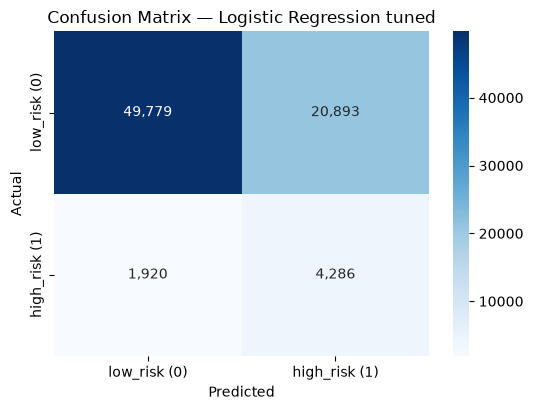

In [13]:
best_model = search.best_estimator_
p_base = baseline_model.predict_proba(X_test)[:, 1]
p_best = best_model.predict_proba(X_test)[:, 1]
y_base = (p_base >= 0.5).astype(int)
y_best = (p_best >= 0.5).astype(int)

def score_row(name, prob, pred):
    tn, fp, fn, tp = confusion_matrix(y_test, pred, labels=[0, 1]).ravel()
    return {
        'Model': name,
        'Balanced Accuracy': balanced_accuracy_score(y_test, pred),
        'ROC-AUC': roc_auc_score(y_test, prob),
        'Average Precision': average_precision_score(y_test, prob),
        'Recall (1)': recall_score(y_test, pred, zero_division=0),
        'Precision (1)': precision_score(y_test, pred, zero_division=0),
        'F1 (1)': f1_score(y_test, pred, zero_division=0),
        'Accuracy': accuracy_score(y_test, pred),
        'TN': int(tn), 'FP': int(fp), 'FN': int(fn), 'TP': int(tp)
    }

comparison = pd.DataFrame([
    score_row('LR baseline', p_base, y_base),
    score_row('LR tuned (selected by CV)', p_best, y_best)
])
display(comparison)

# JSON đúng tên/định dạng shared metrics của nhóm — để compare_models.py sử dụng.
final_result = evaluate_and_save(
    model_name='Logistic Regression', filename='member1_logistic_regression',
    y_true=y_test, y_pred=y_best, y_prob=p_best
)
plot_confusion_matrix(y_test, y_best, model_name='Logistic Regression tuned')

## 5. Biểu đồ đánh giá và Error Analysis
Chụp **ROC + Precision–Recall Curve**, **Confusion Matrix** và bảng metrics ở mục 4 để đưa vào phần **Evaluation & Results**.

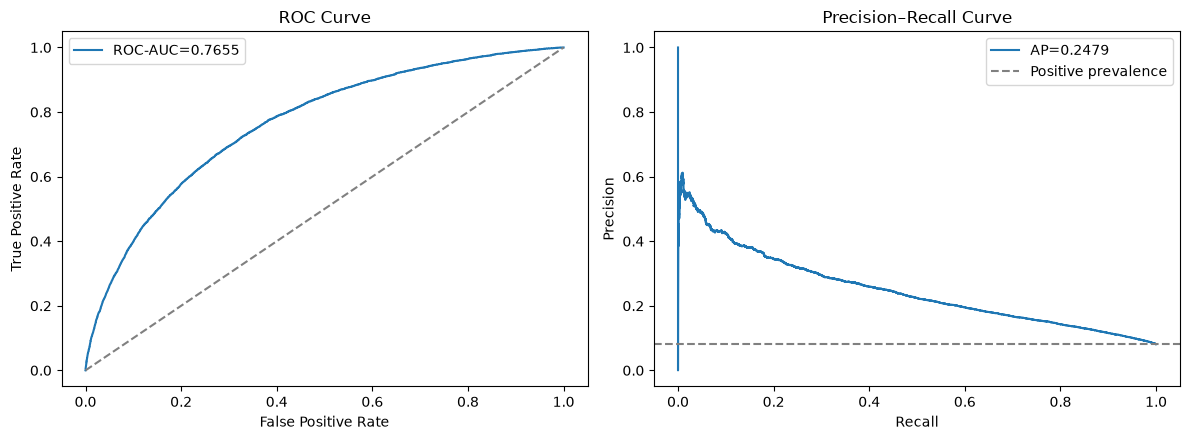

TP=4,286 | FP=20,893 | FN=1,920 | TN=49,779
Bỏ sót trong lớp 1: 30.94% | Cảnh báo nhầm trong cảnh báo lớp 1: 82.98%


In [5]:
fpr, tpr, _ = roc_curve(y_test, p_best)
precision_curve, recall_curve, _ = precision_recall_curve(y_test, p_best)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].plot(fpr, tpr, label=f'ROC-AUC={roc_auc_score(y_test, p_best):.4f}')
axes[0].plot([0, 1], [0, 1], '--', color='gray')
axes[0].set(xlabel='False Positive Rate', ylabel='True Positive Rate', title='ROC Curve')
axes[0].legend()
axes[1].plot(recall_curve, precision_curve,
             label=f'AP={average_precision_score(y_test, p_best):.4f}')
axes[1].axhline(y_test.mean(), linestyle='--', color='gray', label='Positive prevalence')
axes[1].set(xlabel='Recall', ylabel='Precision', title='Precision–Recall Curve')
axes[1].legend()
plt.tight_layout()
plt.show()

tn, fp, fn, tp = confusion_matrix(y_test, y_best, labels=[0, 1]).ravel()
print(f'TP={tp:,} | FP={fp:,} | FN={fn:,} | TN={tn:,}')
print(f'Bỏ sót trong lớp 1: {fn/(fn+tp):.2%} | Cảnh báo nhầm trong cảnh báo lớp 1: {fp/(fp+tp):.2%}')

## 6. Giải thích mô hình – hệ số Logistic Regression
Vì các feature đã qua StandardScaler, có thể xem dấu và độ lớn tương đối của hệ số; không được diễn giải đây là quan hệ nhân quả. Các biến phân loại được core mã hóa số nguyên nên cần đặc biệt thận trọng khi diễn giải hệ số.

,Feature,Coefficient,Absolute coefficient
2,AMT_CREDIT,0.415161,0.415161
4,AMT_GOODS_PRICE,-0.375633,0.375633
14,BASEMENTAREA_MEDI,0.322497,0.322497
10,BASEMENTAREA_AVG,-0.313058,0.313058
1,DAYS_EMPLOYED_ANOM,-0.221108,0.221108
112,EXT_SOURCE_3,-0.219787,0.219787
84,EXT_SOURCE_MAX,-0.211644,0.211644
53,credit_annuity_ratio,-0.204222,0.204222
50,EXT_SOURCE_STD,0.199713,0.199713
37,ELEVATORS_MODE,0.182760,0.182760


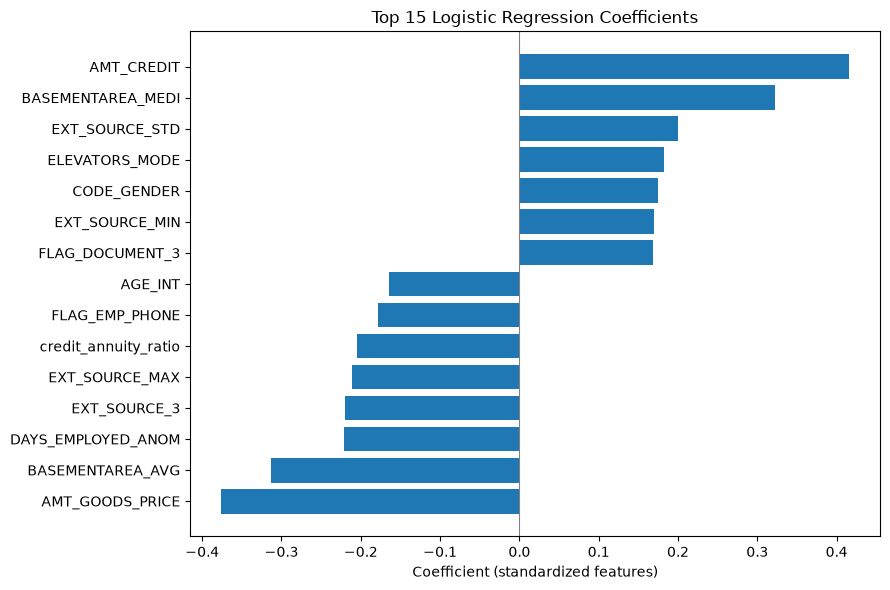

In [6]:
coef = pd.DataFrame({
    'Feature': feature_names,
    'Coefficient': best_model.coef_.ravel()
})
coef['Absolute coefficient'] = coef['Coefficient'].abs()
top_coef = coef.nlargest(15, 'Absolute coefficient')
display(top_coef)
plot_data = top_coef.sort_values('Coefficient')
plt.figure(figsize=(9, 6))
plt.barh(plot_data['Feature'], plot_data['Coefficient'])
plt.axvline(0, color='gray', linewidth=0.8)
plt.xlabel('Coefficient (standardized features)')
plt.title('Top 15 Logistic Regression Coefficients')
plt.tight_layout()
plt.show()